# CMPS261 Project: Amazon ESCI query–product relevance
**Authors:** Allie Saoud, Zulfiquar Fneiche · Project option 4.2

Task: for a shopping query and a product, predict Exact (E), Substitute (S), Complement (C) or Irrelevant (I).
This notebook holds all the code: data cleaning and processing, features, baselines, cross-encoder training,
hyper-parameter tuning, model selection, diagnosis and the final test evaluation.

Heavy steps were run on GCP VMs with one NVIDIA L4 GPU each (see `infra/`). Set the flags below to `True` to rerun them;
with the default `False` the notebook loads the saved outputs in `results/`.

In [1]:
RUN_PREP = False      # download-free: needs raw/examples.parquet and raw/products.parquet
RUN_FEATS = False
RUN_BASELINES = False # LightGBM and logistic regression grids (CPU, about 1.5 h)
RUN_TRAIN = False     # cross-encoder fine-tuning (GPU)
RUN_TEST = False      # final one-time test evaluation

## 0. Shared helpers
Paths and the metric function used everywhere (micro-F1, macro-F1, per-class F1, confusion matrix).

In [2]:
%%writefile common.py
import json
import numpy as np, pandas as pd
from sklearn.metrics import f1_score, confusion_matrix

import os
ROOT = os.path.dirname(os.path.abspath(__file__))
D = os.path.join(ROOT, 'data')
R = os.path.join(ROOT, 'results')
LAB = ['E', 'S', 'C', 'I']

def metrics(y, pred):
    return {'micro_f1': round(float(f1_score(y, pred, average='micro')), 4),
            'macro_f1': round(float(f1_score(y, pred, average='macro')), 4),
            'per_class_f1': dict(zip(LAB, [round(float(v), 4) for v in f1_score(y, pred, average=None, labels=[0, 1, 2, 3])])),
            'confusion': confusion_matrix(y, pred, labels=[0, 1, 2, 3]).tolist()}

def save(name, obj):
    import os; os.makedirs(R, exist_ok=True)
    json.dump(obj, open(f'{R}/{name}.json', 'w'), indent=1)


Overwriting common.py


In [3]:
if False:
    !python common.py

## 1. Data cleaning and preprocessing
US locale, reduced set (`small_version == 1`). HTML unescape, tag removal, whitespace normalisation, lowercasing.
Validation = 10% of training queries (seed 42), grouped by query. The official test split is held out.

In [4]:
%%writefile prep.py
"""Preprocessing for ESCI (US locale, reduced 'small_version' set).
Outputs train/val/test parquet files with cleaned text fields."""
import re, html, json
import numpy as np, pandas as pd, pyarrow.parquet as pq, pyarrow.compute as pc

import os
ROOT = os.path.dirname(os.path.abspath(__file__))
RAW = os.path.join(ROOT, 'raw')
OUT = os.path.join(ROOT, 'data')
import os; os.makedirs(OUT, exist_ok=True)

ex = pd.read_parquet(f'{RAW}/examples.parquet')
ex = ex[(ex.product_locale == 'us') & (ex.small_version == 1)].copy()
stats = {'pairs_raw': len(ex)}

tbl = pq.read_table(f'{RAW}/products.parquet',
                    columns=['product_id', 'product_title', 'product_description',
                             'product_bullet_point', 'product_brand', 'product_color', 'product_locale'],
                    filters=[('product_locale', '=', 'us')])
prod = tbl.to_pandas().drop(columns='product_locale')
prod = prod[prod.product_id.isin(set(ex.product_id))]

TAG = re.compile(r'<[^>]+>')
WS = re.compile(r'\s+')
def clean(s, maxlen=None):
    if s is None or (isinstance(s, float) and np.isnan(s)):
        return ''
    s = html.unescape(str(s))
    s = TAG.sub(' ', s)
    s = s.replace(' ', ' ')
    s = WS.sub(' ', s).strip().lower()
    if maxlen:
        s = s[:maxlen]
    return s

missing = {c: float((prod[c].fillna('').str.strip() == '').mean())
           for c in ['product_title', 'product_description', 'product_bullet_point', 'product_brand', 'product_color']}
for c, m in [('product_title', None), ('product_brand', None), ('product_color', None),
             ('product_bullet_point', 1000), ('product_description', 1000)]:
    prod[c] = [clean(x, m) for x in prod[c].values]

df = ex.merge(prod, on='product_id', how='left')
for c in ['product_title', 'product_description', 'product_bullet_point', 'product_brand', 'product_color']:
    df[c] = df[c].fillna('')
df['query_clean'] = [clean(q) for q in df['query'].values]
stats['pairs_missing_product'] = int((df.product_title == '').sum())
stats['dup_pairs'] = int(df.duplicated(['query_id', 'product_id']).sum())
df = df.drop_duplicates(['query_id', 'product_id'])

# Query-grouped validation split (10% of train queries), official test held out.
rng = np.random.RandomState(42)
tr_q = df.loc[df.split == 'train', 'query_id'].unique()
val_q = set(rng.choice(tr_q, size=int(0.1 * len(tr_q)), replace=False))
df['part'] = np.where(df.split == 'test', 'test', np.where(df.query_id.isin(val_q), 'val', 'train'))

LABELS = {'E': 0, 'S': 1, 'C': 2, 'I': 3}
df['y'] = df.esci_label.map(LABELS)
keep = ['example_id', 'query_id', 'query', 'query_clean', 'product_id', 'product_title', 'product_brand',
        'product_color', 'product_bullet_point', 'product_description', 'esci_label', 'y', 'part']
for p in ['train', 'val', 'test']:
    d = df[df.part == p][keep]
    d.to_parquet(f'{OUT}/{p}.parquet', index=False)
    stats[p] = {'pairs': len(d), 'queries': int(d.query_id.nunique()),
                'label_dist': d.esci_label.value_counts(normalize=True).round(4).to_dict()}
stats['missing_rate_products'] = {k: round(v, 4) for k, v in missing.items()}
stats['n_products'] = len(prod)
stats['query_len_words_mean'] = float(df.query_clean.str.split().str.len().mean())
stats['title_len_words_mean'] = float(df.product_title.str.split().str.len().mean())
json.dump(stats, open(f'{OUT}/prep_stats.json', 'w'), indent=1)
print(json.dumps(stats, indent=1))


Overwriting prep.py


In [5]:
if RUN_PREP:
    !python prep.py

## 2. Feature engineering
33 lexical query–product features and sparse TF-IDF matrices (fit on training data only).

In [6]:
%%writefile feats.py
"""Lexical query-product features + sparse TF-IDF matrices for the classical baseline."""
import re, math, json, pickle
from collections import Counter
import numpy as np, pandas as pd, scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer

import os
D = os.path.join(os.path.dirname(os.path.abspath(__file__)), 'data')
parts = {p: pd.read_parquet(f'{D}/{p}.parquet') for p in ['train', 'val', 'test']}
TOK = re.compile(r'[a-z0-9]+(?:[.\-][a-z0-9]+)*')
NUM = re.compile(r'\d')
NEG = {'not', 'without', 'no', 'non', 'free', 'except'}
COMP_WORDS = {'for', 'compatible', 'case', 'cover', 'replacement', 'charger', 'cable', 'adapter',
              'protector', 'accessory', 'accessories', 'kit', 'refill', 'holder', 'mount', 'stand', 'strap'}

def toks(s):
    return TOK.findall(s)

# document frequency over product titles in train (for IDF-weighted overlap / BM25)
tr_titles = parts['train'].drop_duplicates('product_id').product_title.values
df_cnt = Counter()
for t in tr_titles:
    df_cnt.update(set(toks(t)))
N = len(tr_titles)
def idf(w):
    return math.log((N - df_cnt.get(w, 0) + 0.5) / (df_cnt.get(w, 0) + 0.5) + 1)
avg_tl = np.mean([len(toks(t)) for t in tr_titles])

def char_ngrams(s, n=3):
    s = f' {s} '
    return {s[i:i + n] for i in range(len(s) - n + 1)}

def bm25(q, d, k1=1.2, b=0.75):
    tf = Counter(d); L = len(d); sc = 0.0
    for w in set(q):
        f = tf.get(w, 0)
        if f:
            sc += idf(w) * f * (k1 + 1) / (f + k1 * (1 - b + b * L / avg_tl))
    return sc

def row(q, title, brand, color, bullet, desc):
    qt, tt, bt, dt = toks(q), toks(title), toks(bullet), toks(desc)
    qs, ts, bs, ds = set(qt), set(tt), set(bt), set(dt)
    brs, cs = set(toks(brand)), set(toks(color))
    nq = max(len(qs), 1)
    qidf = sum(idf(w) for w in qs) or 1.0
    qnum = {w for w in qs if NUM.search(w)}
    qc, tc = char_ngrams(q), char_ngrams(title)
    miss = qs - ts - bs - brs
    f = {
        'q_len': len(qt), 't_len': len(tt), 'b_len': len(bt), 'd_len': len(dt),
        'has_desc': int(bool(dt)), 'has_bullet': int(bool(bt)), 'has_brand': int(bool(brs)),
        'ov_title': len(qs & ts) / nq, 'ov_bullet': len(qs & bs) / nq, 'ov_desc': len(qs & ds) / nq,
        'ov_brand': len(qs & brs) / nq, 'ov_color': len(qs & cs) / nq,
        'ov_any': len(qs & (ts | bs | ds | brs | cs)) / nq,
        'idf_ov_title': sum(idf(w) for w in qs & ts) / qidf,
        'idf_ov_any': sum(idf(w) for w in qs & (ts | bs | ds | brs)) / qidf,
        'jacc_title': len(qs & ts) / max(len(qs | ts), 1),
        'char_jacc': len(qc & tc) / max(len(qc | tc), 1),
        'char_cov': len(qc & tc) / max(len(qc), 1),
        'bm25_title': bm25(qt, tt), 'bm25_bullet': bm25(qt, bt), 'bm25_desc': bm25(qt, dt),
        'q_num': len(qnum), 'num_match': len(qnum & (ts | bs)) / max(len(qnum), 1) if qnum else -1,
        'brand_in_q': int(bool(brs) and brs <= qs),
        'max_missing_idf': max([idf(w) for w in miss], default=0.0),
        'n_missing': len(miss),
        'q_neg': int(bool(qs & NEG)),
        't_comp_words': len(ts & COMP_WORDS), 'q_comp_words': len(qs & COMP_WORDS),
        'title_for_after_q': int(' for ' in title and any(w in title.split(' for ', 1)[1] for w in qs)),
        'first_q_in_title': int(bool(qt) and qt[0] in ts), 'last_q_in_title': int(bool(qt) and qt[-1] in ts),
        'q_mean_idf': qidf / nq,
    }
    return f

for p, d in parts.items():
    F = pd.DataFrame([row(*r) for r in zip(d.query_clean.values, d.product_title.values, d.product_brand.values,
                                          d.product_color.values, d.product_bullet_point.values,
                                          d.product_description.values)])
    F.to_parquet(f'{D}/feat_{p}.parquet', index=False)
    print(p, F.shape)

# Sparse text representation: TF-IDF of query, of title, and their element-wise product (shared terms)
vec_w = TfidfVectorizer(token_pattern=r'[a-z0-9]+', ngram_range=(1, 2), min_df=3, max_features=300000,
                        sublinear_tf=True, dtype=np.float32)
vec_c = TfidfVectorizer(analyzer='char_wb', ngram_range=(3, 4), min_df=5, max_features=200000,
                        sublinear_tf=True, dtype=np.float32)
tr = parts['train']
vec_w.fit(pd.concat([tr.query_clean, tr.drop_duplicates('product_id').product_title]))
vec_c.fit(pd.concat([tr.query_clean, tr.drop_duplicates('product_id').product_title]))
for p, d in parts.items():
    Qw, Tw = vec_w.transform(d.query_clean), vec_w.transform(d.product_title)
    Qc, Tc = vec_c.transform(d.query_clean), vec_c.transform(d.product_title)
    X = sp.hstack([Qw, Tw, Qw.multiply(Tw), Qc.multiply(Tc)]).tocsr().astype(np.float32)
    sp.save_npz(f'{D}/tfidf_{p}.npz', X)
    print(p, X.shape, X.nnz)


Overwriting feats.py


In [7]:
if RUN_FEATS:
    !python feats.py

## 3. Classical baselines and hyper-parameter tuning
LightGBM (8 settings) and logistic regression on TF-IDF (8 settings); selection by validation micro-F1.

In [8]:
%%writefile baseline.py
"""Classical baselines, tuned on the query-grouped validation split."""
import time, itertools, sys, os
import numpy as np, pandas as pd, scipy.sparse as sp
from joblib import Parallel, delayed
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
import lightgbm as lgb
from common import *

tr, va = pd.read_parquet(f'{D}/train.parquet'), pd.read_parquet(f'{D}/val.parquet')
ytr, yva = tr.y.values, va.y.values
Ftr, Fva = pd.read_parquet(f'{D}/feat_train.parquet'), pd.read_parquet(f'{D}/feat_val.parquet')
out = {'majority': metrics(yva, np.zeros_like(yva))}
print('majority', out['majority']['micro_f1'], out['majority']['macro_f1'], flush=True)

# --- LightGBM on hand-crafted lexical features
lgb_grid = []
for nl, mcs, cw in itertools.product([31, 127], [50, 200], [None, 'balanced']):
    t = time.time()
    m = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.05, num_leaves=nl, min_child_samples=mcs,
                           subsample=0.8, subsample_freq=1, colsample_bytree=0.8, class_weight=cw,
                           n_jobs=-1, verbose=-1)
    m.fit(Ftr, ytr, eval_set=[(Fva, yva)], callbacks=[lgb.early_stopping(50, verbose=False)])
    r = metrics(yva, m.predict(Fva))
    r.update(params={'num_leaves': nl, 'min_child_samples': mcs, 'class_weight': cw}, best_iter=int(m.best_iteration_),
             secs=round(time.time() - t))
    lgb_grid.append(r); print('lgb', r['params'], r['best_iter'], r['micro_f1'], r['macro_f1'], flush=True)
    if r is max(lgb_grid, key=lambda r: r['micro_f1']):
        np.save(f'{R}/lgb_val_proba.npy', m.predict_proba(Fva))
        gain = m.booster_.feature_importance(importance_type='gain')
        out['best_lgb_importance_gain'] = sorted(zip(Ftr.columns.tolist(), [float(g) for g in gain]), key=lambda kv: -kv[1])
    save('baseline_partial_full', {**out, 'lgb_grid': lgb_grid})
best_lgb = max(lgb_grid, key=lambda r: r['micro_f1'])
out['lgb_grid'] = lgb_grid

# --- Logistic regression on TF-IDF (query, title, query*title word & char) + scaled lexical features
Xtr, Xva = sp.load_npz(f'{D}/tfidf_train.npz'), sp.load_npz(f'{D}/tfidf_val.npz')
sc = StandardScaler().fit(Ftr)
Xtr = sp.hstack([Xtr, sp.csr_matrix(sc.transform(Ftr).astype(np.float32))]).tocsr()
Xva = sp.hstack([Xva, sp.csr_matrix(sc.transform(Fva).astype(np.float32))]).tocsr()
def fit_lr(Xtr, ytr, Xva, yva, C, cw, max_iter=300):
    t = time.time()
    m = LogisticRegression(C=C, class_weight=cw, max_iter=max_iter, solver='lbfgs')
    m.fit(Xtr, ytr)
    p = m.predict_proba(Xva)
    r = metrics(yva, p.argmax(1))
    n_iter = int(np.max(m.n_iter_))
    r.update(params={'C': C, 'class_weight': cw}, n_iter=n_iter, converged=n_iter < max_iter, secs=round(time.time() - t))
    print('lr', r['params'], r['n_iter'], r['micro_f1'], r['macro_f1'], r['secs'], flush=True)
    return r, p

# lbfgs is effectively single-threaded here, so the 8 settings run as separate processes.
res = Parallel(n_jobs=int(os.environ.get('LR_JOBS', 8)), backend='loky')(
    delayed(fit_lr)(Xtr, ytr, Xva, yva, C, cw) for C, cw in itertools.product([0.1, 0.3, 1.0, 3.0], [None, 'balanced']))
lr_grid = [r for r, _ in res]
np.save(f'{R}/lr_val_proba.npy', max(res, key=lambda rp: rp[0]['micro_f1'])[1])
out['lr_grid'] = lr_grid
out['best_lgb'] = best_lgb
out['best_lr'] = max(lr_grid, key=lambda r: r['micro_f1'])
save('baseline', out)


Overwriting baseline.py


In [9]:
if RUN_BASELINES:
    !python baseline.py

### 3b. Logistic regression until convergence
The first run stopped at 300 iterations. This reruns the same grid with a higher limit.

In [10]:
%%writefile lr_converge.py
"""Rerun the logistic-regression grid from baseline.py with a higher iteration limit, so the fits converge.
Same features and grid as baseline.py; only max_iter changes (300 -> MAX_ITER, default 3000)."""
import time, itertools, os
import numpy as np, pandas as pd, scipy.sparse as sp, joblib
from joblib import Parallel, delayed
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from common import *

MAX_ITER = int(os.environ.get('MAX_ITER', 3000))
tr, va = pd.read_parquet(f'{D}/train.parquet'), pd.read_parquet(f'{D}/val.parquet')
ytr, yva = tr.y.values, va.y.values
Ftr, Fva = pd.read_parquet(f'{D}/feat_train.parquet'), pd.read_parquet(f'{D}/feat_val.parquet')
Xtr, Xva = sp.load_npz(f'{D}/tfidf_train.npz'), sp.load_npz(f'{D}/tfidf_val.npz')
sc = StandardScaler().fit(Ftr)
Xtr = sp.hstack([Xtr, sp.csr_matrix(sc.transform(Ftr).astype(np.float32))]).tocsr()
Xva = sp.hstack([Xva, sp.csr_matrix(sc.transform(Fva).astype(np.float32))]).tocsr()

def fit_lr(C, cw):
    t = time.time()
    m = LogisticRegression(C=C, class_weight=cw, max_iter=MAX_ITER, solver='lbfgs')
    m.fit(Xtr, ytr)
    p = m.predict_proba(Xva)
    r = metrics(yva, p.argmax(1))
    n_iter = int(np.max(m.n_iter_))
    r.update(params={'C': C, 'class_weight': cw}, n_iter=n_iter, converged=n_iter < MAX_ITER, secs=round(time.time() - t))
    print('lr', r['params'], r['n_iter'], r['micro_f1'], r['macro_f1'], r['secs'], flush=True)
    return r, p, m

res = Parallel(n_jobs=int(os.environ.get('LR_JOBS', 8)), backend='loky')(
    delayed(fit_lr)(C, cw) for C, cw in itertools.product([0.1, 0.3, 1.0, 3.0], [None, 'balanced']))
best_r, best_p, best_m = max(res, key=lambda x: x[0]['micro_f1'])
np.save(f'{R}/lr_conv_val_proba.npy', best_p)
os.makedirs(f'{ROOT}/models', exist_ok=True)
joblib.dump({'scaler': sc, 'model': best_m}, f'{ROOT}/models/lr_best.joblib')
save('lr_converged', {'max_iter': MAX_ITER, 'lr_grid': [r for r, _, _ in res], 'best_lr': best_r})


Overwriting lr_converge.py


In [11]:
if RUN_BASELINES:
    !python lr_converge.py

## 4. Cross-encoder fine-tuning
Pretrained cross-encoders with a new 4-class head. The env vars select the model, fields, max length, seed,
training fraction and class weights. `run_experiments.sh` lists every configuration we ran.

In [12]:
%%writefile xenc_pretrained.py
"""Fine-tune a pretrained cross-encoder for 4-way ESCI classification. Configured through env vars.

Defaults reproduce the runs in the progress report. Extra options (all optional):
  FIELDS  comma list of product fields for text B, from title,brandcolor,bullets,desc
          (default title,brandcolor,bullets)
  FRAC    fraction of training queries to keep, grouped by query (default 1.0 = all)
  CW      'balanced' to weight the loss by inverse class frequency (default: no weights)
  SAVE    1 to save the best checkpoint to models/{TAG} (default 1)
"""
import os, time, math
import numpy as np, pandas as pd, torch, torch.nn.functional as F
import transformers
from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup, set_seed
from common import *

MODEL = os.environ.get('MODEL', 'cross-encoder/ms-marco-MiniLM-L-6-v2')
TAG = os.environ.get('TAG', 'minilm')
MAXLEN = int(os.environ.get('MAXLEN', 128)); EPOCHS = int(os.environ.get('EPOCHS', 2))
BS = int(os.environ.get('BS', 64)); LR = float(os.environ.get('LR', 3e-5))
EVAL_STEPS = int(os.environ.get('EVAL_STEPS', 2000)); SEED = int(os.environ.get('SEED', 0))
EVAL_BS = int(os.environ.get('EVAL_BS', 256))
FIELDS = os.environ.get('FIELDS', 'title,brandcolor,bullets').split(',')
FRAC = float(os.environ.get('FRAC', 1.0)); CW = os.environ.get('CW', '')
SAVE = os.environ.get('SAVE', '1') == '1'

set_seed(SEED)
dev = 'cuda' if torch.cuda.is_available() else 'mps' if torch.backends.mps.is_available() else 'cpu'
amp = dev == 'cuda'
print('device', dev, 'model', MODEL, 'fields', FIELDS, 'frac', FRAC, 'cw', CW or 'none', flush=True)

tr, va = pd.read_parquet(f'{D}/train.parquet'), pd.read_parquet(f'{D}/val.parquet')
if FRAC < 1:
    # Learning curve: keep a random subset of training queries (fixed seed 0, independent of SEED).
    q = tr.query_id.unique()
    keep = set(np.random.RandomState(0).choice(q, size=int(FRAC * len(q)), replace=False))
    tr = tr[tr.query_id.isin(keep)].reset_index(drop=True)
print('train pairs', len(tr), flush=True)
tok = AutoTokenizer.from_pretrained(MODEL)

def second(d):
    """Text B: the chosen product fields joined by the separator token."""
    s = f' {tok.sep_token} '
    parts = {'title': d.product_title, 'brandcolor': d.product_brand + ' ' + d.product_color,
             'bullets': d.product_bullet_point.str.slice(0, 300), 'desc': d.product_description.str.slice(0, 300)}
    out = parts[FIELDS[0]]
    for f in FIELDS[1:]:
        out = out + s + parts[f]
    return out.tolist()

def encode(d):
    return tok(d.query_clean.tolist(), second(d), truncation='only_second', max_length=MAXLEN, padding='max_length', return_tensors='pt')

t0 = time.time()
Etr, Eva = encode(tr), encode(va)
ytr, yva = torch.tensor(tr.y.values), va.y.values
print('encoded', Etr['input_ids'].shape, round(time.time() - t0), 's', flush=True)

model = AutoModelForSequenceClassification.from_pretrained(MODEL, num_labels=4, ignore_mismatched_sizes=True, dtype=torch.float32).to(dev)
n_params = sum(p.numel() for p in model.parameters())
print('params', n_params, flush=True)

weight = None
if CW == 'balanced':
    cnt = np.bincount(tr.y.values, minlength=4)
    weight = torch.tensor(len(tr) / (4 * cnt), dtype=torch.float32, device=dev)
    print('class weights', weight.tolist(), flush=True)

steps = EPOCHS * math.ceil(len(ytr) / BS)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=0.01)
sched = get_linear_schedule_with_warmup(opt, int(0.05 * steps), steps)
scaler = torch.amp.GradScaler('cuda', enabled=amp)

@torch.no_grad()
def predict():
    model.eval(); out = []
    for i in range(0, len(yva), EVAL_BS):
        b = {k: v[i:i + EVAL_BS].to(dev) for k, v in Eva.items()}
        with torch.amp.autocast('cuda', enabled=amp):
            out.append(F.softmax(model(**b).logits.float(), -1).cpu())
    model.train(); return torch.cat(out).numpy()

config = dict(model=MODEL, MAXLEN=MAXLEN, EPOCHS=EPOCHS, BS=BS, LR=LR, SEED=SEED, warmup=0.05, weight_decay=0.01,
              FIELDS=FIELDS, FRAC=FRAC, CW=CW or None, train_pairs=len(tr),
              params=n_params, device=dev, transformers=transformers.__version__, torch=torch.__version__,
              gpu=torch.cuda.get_device_name(0) if dev == 'cuda' else None)
log = []; step = 0; best = -1; t_train = time.time()

def evaluate(ep):
    global best
    t = time.time(); p = predict(); infer = time.time() - t
    r = metrics(yva, p.argmax(1))
    r.update(step=step, epoch=ep, secs=round(time.time() - t_train), val_infer_secs=round(infer, 1))
    if dev == 'cuda':
        r['peak_gpu_mem_gb'] = round(torch.cuda.max_memory_allocated() / 2**30, 2)
    log.append(r); print('VAL', step, r['micro_f1'], r['macro_f1'], r['per_class_f1'], flush=True)
    if r['micro_f1'] > best:
        best = r['micro_f1']; np.save(f'{R}/{TAG}_val_proba.npy', p)
        if SAVE:
            model.save_pretrained(f'{ROOT}/models/{TAG}')
    save(TAG, {'config': config, 'log': log, 'best': max(log, key=lambda r: r['micro_f1'])})

model.train()
for ep in range(EPOCHS):
    perm = torch.randperm(len(ytr)); run = 0; t = time.time()
    for i in range(0, len(perm), BS):
        idx = perm[i:i + BS]
        b = {k: v[idx].to(dev) for k, v in Etr.items()}
        with torch.amp.autocast('cuda', enabled=amp):
            loss = F.cross_entropy(model(**b).logits, ytr[idx].to(dev), weight=weight)
        opt.zero_grad(set_to_none=True)
        scaler.scale(loss).backward(); scaler.unscale_(opt)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(opt); scaler.update(); sched.step()
        step += 1; run += loss.item()
        if step % 200 == 0:
            print(f'ep {ep} step {step}/{steps} loss {run / 200:.4f} {time.time() - t:.0f}s', flush=True); run = 0
        if step % EVAL_STEPS == 0 or step == steps:
            evaluate(ep)
print('done', round(time.time() - t_train), 's', flush=True)


Overwriting xenc_pretrained.py


In [13]:
if RUN_TRAIN:
    !bash run_experiments.sh

## 5. Failure analysis on validation
Accuracy on slices fixed before looking at results.

In [14]:
%%writefile error_analysis.py
"""Slice validation predictions to see where models fail. Every threshold is fixed here, before looking at results."""
import re, glob, os
import numpy as np, pandas as pd
from sklearn.metrics import accuracy_score
from common import *

HIGH_OV, LOW_OV = 0.75, 0.25
TOK = re.compile(r'[a-z0-9]+(?:[.\-][a-z0-9]+)*')
va = pd.read_parquet(f'{D}/val.parquet'); F = pd.read_parquet(f'{D}/feat_val.parquet')
tr = pd.read_parquet(f'{D}/train.parquet', columns=['product_id', 'product_title', 'product_bullet_point'])
y = va.y.values

# A likely misspelling: an alphabetic query word of 4+ letters that appears in no training title or bullet text.
prod = tr.drop_duplicates('product_id')
vocab = set()
for col in ('product_title', 'product_bullet_point'):
    for s in prod[col].values:
        vocab.update(TOK.findall(s))
misspelled = np.array([any(w.isalpha() and len(w) >= 4 and w not in vocab for w in TOK.findall(q)) for q in va.query_clean.values])

base = load = __import__('json').load(open(f'{R}/baseline.json'))
lgb_micro, lr_micro = base['best_lgb']['micro_f1'], base['best_lr']['micro_f1']
preds = {'best_baseline': np.load(f'{R}/{"lgb" if lgb_micro >= lr_micro else "lr"}_val_proba.npy').argmax(1)}
for name in ('minilm', 'deberta_small', 'deberta_base'):
    path = f'{R}/{name}_val_proba.npy'
    if os.path.exists(path):
        preds[name] = np.load(path).argmax(1)

slices = {
    'all': np.ones_like(y, dtype=bool),
    'high_overlap_labelled_I_or_C': (F.ov_title.values >= HIGH_OV) & np.isin(y, [2, 3]),
    'low_overlap_labelled_E': (F.ov_title.values <= LOW_OV) & (y == 0),
    'likely_misspelled_query': misspelled,
    'query_has_number': F.q_num.values > 0,
    'query_has_negation': F.q_neg.values > 0,
}
out = {'thresholds': {'high_overlap_ov_title_ge': HIGH_OV, 'low_overlap_ov_title_le': LOW_OV,
                      'misspelled': 'alphabetic query token, 4+ letters, absent from train titles and bullets'},
       'best_baseline_source': 'lgb' if lgb_micro >= lr_micro else 'lr', 'slices': {}}
for name, mask in slices.items():
    out['slices'][name] = {'n_pairs': int(mask.sum()), 'share': round(float(mask.mean()), 4), 'n_queries': int(va.query_id[mask].nunique()),
                           'label_counts': dict(zip(LAB, np.bincount(y[mask], minlength=4).tolist()))}
    for m, p in preds.items():
        s = {'accuracy': round(float(accuracy_score(y[mask], p[mask])), 4),
             'pred_counts': dict(zip(LAB, np.bincount(p[mask], minlength=4).tolist()))}
        if name in ('all', 'likely_misspelled_query', 'query_has_number', 'query_has_negation'):
            k = metrics(y[mask], p[mask]); s.update(micro_f1=k['micro_f1'], macro_f1=k['macro_f1'], per_class_f1=k['per_class_f1'])
        out['slices'][name][m] = s

comp = y == 2
out['complement'] = {m: {'n': int(comp.sum()), 'pred_counts': dict(zip(LAB, np.bincount(p[comp], minlength=4).tolist())),
                         'recall': round(float((p[comp] == 2).mean()), 4)} for m, p in preds.items()}
save('error_analysis', out)
print(__import__('json').dumps(out, indent=1))


Overwriting error_analysis.py


In [15]:
if RUN_TRAIN:
    !python error_analysis.py

## 6. Hybrid model
LightGBM stacked on cross-encoder probabilities and lexical features, trained on validation and scored with
5-fold cross-validation grouped by query.

In [16]:
%%writefile hybrid.py
"""Hybrid model: LightGBM stacked on cross-encoder probabilities plus the 33 lexical features.
The cross-encoders never saw validation labels in training, so the stacker is trained on the validation split.
We estimate its quality with 5-fold cross-validation grouped by query (out-of-fold predictions), and compare
with the cross-encoders alone on exactly the same pairs. The test split is not used here."""
import os, json
import numpy as np, pandas as pd, lightgbm as lgb
from sklearn.model_selection import GroupKFold
from common import *

va = pd.read_parquet(f'{D}/val.parquet'); Fva = pd.read_parquet(f'{D}/feat_val.parquet'); y = va.y.values
CE = [t for t in ('minilm', 'deberta_small', 'deberta_base') if os.path.exists(f'{R}/{t}_val_proba.npy')]
P = {t: np.load(f'{R}/{t}_val_proba.npy') for t in CE}
ce_scores = {t: json.load(open(f'{R}/{t}.json'))['best']['micro_f1'] for t in CE}
best_ce = max(CE, key=ce_scores.get)
PARAMS = dict(n_estimators=300, learning_rate=0.05, num_leaves=31, min_child_samples=100, subsample=0.8,
              subsample_freq=1, colsample_bytree=0.8, random_state=0, n_jobs=-1, verbose=-1)

def design(variant, F, probs):
    cols = {'lex': F.reset_index(drop=True)}
    use = {'ce_best': [best_ce], 'ce_all': CE}[variant['ce']]
    for t in use:
        cols[t] = pd.DataFrame(probs[t], columns=[f'{t}_{l}' for l in LAB])
    parts = [cols[t] for t in use] + ([cols['lex']] if variant['lex'] else [])
    return pd.concat(parts, axis=1)

VARIANTS = {
    'ce_all_only': {'ce': 'ce_all', 'lex': False, 'cw': None},
    'lex+ce_best': {'ce': 'ce_best', 'lex': True, 'cw': None},
    'lex+ce_all': {'ce': 'ce_all', 'lex': True, 'cw': None},
    'lex+ce_all_balanced': {'ce': 'ce_all', 'lex': True, 'cw': 'balanced'},
}
folds = list(GroupKFold(n_splits=5).split(va, y, groups=va.query_id.values))
out = {'cross_encoders': CE, 'best_cross_encoder': best_ce, 'params': PARAMS, 'variants': {},
       'cross_encoder_alone': {t: metrics(y, P[t].argmax(1)) for t in CE}}
for name, v in VARIANTS.items():
    X = design(v, Fva, P); oof = np.zeros((len(y), 4))
    for tr_i, te_i in folds:
        m = lgb.LGBMClassifier(class_weight=v['cw'], **PARAMS).fit(X.iloc[tr_i], y[tr_i])
        oof[te_i] = m.predict_proba(X.iloc[te_i])
    r = metrics(y, oof.argmax(1)); r['variant'] = v
    out['variants'][name] = r
    np.save(f'{R}/hybrid_{name}_val_oof.npy', oof)
    print(name, r['micro_f1'], r['macro_f1'], r['per_class_f1'], flush=True)
out['selected'] = max(out['variants'], key=lambda k: out['variants'][k]['micro_f1'])
save('hybrid', out)
print('selected', out['selected'])


Overwriting hybrid.py


In [17]:
if RUN_TRAIN:
    !python hybrid.py

## 7. Test predictions for the final models (run once)

In [18]:
%%writefile predict_test.py
"""Predict the held-out test split with saved cross-encoder checkpoints (run once, for the final models only).
Also re-predicts validation as a check that the loaded checkpoint matches the saved validation predictions.
Usage: TAGS=minilm,deberta_small,deberta_base python predict_test.py"""
import os, json, time
import numpy as np, pandas as pd, torch, torch.nn.functional as F
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from common import *

dev = 'cuda' if torch.cuda.is_available() else 'cpu'
va, te = pd.read_parquet(f'{D}/val.parquet'), pd.read_parquet(f'{D}/test.parquet')
out = json.load(open(f'{R}/test_predict_log.json')) if os.path.exists(f'{R}/test_predict_log.json') else {}

for tag in os.environ['TAGS'].split(','):
    cfg = json.load(open(f'{R}/{tag}.json'))['config']
    fields = cfg.get('FIELDS', ['title', 'brandcolor', 'bullets'])
    tok = AutoTokenizer.from_pretrained(cfg['model'])
    model = AutoModelForSequenceClassification.from_pretrained(f'{ROOT}/models/{tag}', dtype=torch.float32).to(dev).eval()

    def second(d):
        s = f' {tok.sep_token} '
        parts = {'title': d.product_title, 'brandcolor': d.product_brand + ' ' + d.product_color,
                 'bullets': d.product_bullet_point.str.slice(0, 300), 'desc': d.product_description.str.slice(0, 300)}
        o = parts[fields[0]]
        for f in fields[1:]:
            o = o + s + parts[f]
        return o.tolist()

    @torch.no_grad()
    def predict(d, bs=512):
        E = tok(d.query_clean.tolist(), second(d), truncation='only_second', max_length=cfg['MAXLEN'],
                padding='max_length', return_tensors='pt')
        ps = []
        for i in range(0, len(d), bs):
            b = {k: v[i:i + bs].to(dev) for k, v in E.items()}
            with torch.amp.autocast('cuda', enabled=dev == 'cuda'):
                ps.append(F.softmax(model(**b).logits.float(), -1).cpu())
        return torch.cat(ps).numpy()

    pv = predict(va)
    saved = np.load(f'{R}/{tag}_val_proba.npy')
    agree = float((pv.argmax(1) == saved.argmax(1)).mean())
    t = time.time(); pt = predict(te); secs = time.time() - t
    np.save(f'{R}/{tag}_test_proba.npy', pt)
    out[tag] = {'val_argmax_agreement_with_saved': round(agree, 5), 'test_pairs': len(te),
                'test_infer_secs': round(secs, 1), 'test_pairs_per_sec': round(len(te) / secs)}
    print(tag, out[tag], flush=True)
    del model; torch.cuda.empty_cache()
save('test_predict_log', out)


Overwriting predict_test.py


In [19]:
if RUN_TEST:
    !TAGS=minilm,deberta_small,deberta_base python predict_test.py

## 8. Final test evaluation (run once)

In [20]:
%%writefile final_test.py
"""Final, one-time evaluation on the held-out test split.
Models were selected on validation before this script was run. Writes results/test.json."""
import os, re, json, time
import numpy as np, pandas as pd, scipy.sparse as sp, joblib, lightgbm as lgb
from sklearn.metrics import accuracy_score
from common import *
import hybrid as H   # re-runs the validation-only hybrid CV and gives the selected variant and its design

tr, va, te = (pd.read_parquet(f'{D}/{p}.parquet') for p in ('train', 'val', 'test'))
Ftr, Fva, Fte = (pd.read_parquet(f'{D}/feat_{p}.parquet') for p in ('train', 'val', 'test'))
ytr, yva, yte = tr.y.values, va.y.values, te.y.values
out = {'test_pairs': len(te), 'test_queries': int(te.query_id.nunique()), 'models': {}, 'val': {}}
pred = {}

# Majority class
pred['majority'] = np.zeros_like(yte)

# LightGBM: refit the selected baseline setting exactly as in baseline.py, then predict test once.
base = json.load(open(f'{R}/baseline.json'))['best_lgb']['params']
t = time.time()
m = lgb.LGBMClassifier(n_estimators=2000, learning_rate=0.05, num_leaves=base['num_leaves'], min_child_samples=base['min_child_samples'],
                       subsample=0.8, subsample_freq=1, colsample_bytree=0.8, class_weight=base['class_weight'], n_jobs=-1, verbose=-1)
m.fit(Ftr, ytr, eval_set=[(Fva, yva)], callbacks=[lgb.early_stopping(50, verbose=False)])
out['val']['lightgbm_refit'] = dict(metrics(yva, m.predict(Fva)), best_iter=int(m.best_iteration_), fit_secs=round(time.time() - t))
m.booster_.save_model(f'{ROOT}/models/lgb_best.txt')
t = time.time(); pred['lightgbm'] = m.predict(Fte); out['val']['lightgbm_refit']['test_infer_secs'] = round(time.time() - t, 1)

# Logistic regression (converged rerun)
if os.path.exists(f'{ROOT}/models/lr_best.joblib'):
    lr = joblib.load(f'{ROOT}/models/lr_best.joblib')
    Xte = sp.hstack([sp.load_npz(f'{D}/tfidf_test.npz'), sp.csr_matrix(lr['scaler'].transform(Fte).astype(np.float32))]).tocsr()
    pred['logistic_regression'] = lr['model'].predict(Xte)

# Cross-encoders
P_te = {}
for tag in H.CE:
    path = f'{R}/{tag}_test_proba.npy'
    if os.path.exists(path):
        P_te[tag] = np.load(path); pred[tag] = P_te[tag].argmax(1)

# Hybrid: fit the variant selected by validation CV on all validation pairs, predict test.
sel = H.out['selected']; v = H.VARIANTS[sel]
hm = lgb.LGBMClassifier(class_weight=v['cw'], **H.PARAMS).fit(H.design(v, Fva, H.P), yva)
pred[f'hybrid_{sel}'] = hm.predict(H.design(v, Fte, P_te)).astype(int)
hm.booster_.save_model(f'{ROOT}/models/hybrid_lgb.txt')
out['hybrid_selected'] = sel

# Final model = highest validation micro-F1 (hybrid scored out-of-fold), decided without test labels.
val_scores = {'lightgbm': json.load(open(f'{R}/baseline.json'))['best_lgb']['micro_f1'],
              f'hybrid_{sel}': H.out['variants'][sel]['micro_f1']}
if 'logistic_regression' in pred:
    val_scores['logistic_regression'] = json.load(open(f'{R}/lr_converged.json'))['best_lr']['micro_f1']
for tag in P_te:
    val_scores[tag] = json.load(open(f'{R}/{tag}.json'))['best']['micro_f1']
out['val_micro_used_for_selection'] = val_scores
out['final_model'] = max(val_scores, key=val_scores.get)
print('final model (chosen on validation):', out['final_model'], flush=True)

for k, p in pred.items():
    out['models'][k] = metrics(yte, p)
    print(k, out['models'][k]['micro_f1'], out['models'][k]['macro_f1'], out['models'][k]['per_class_f1'], flush=True)

# Failure slices on test, same definitions as error_analysis.py
TOK = re.compile(r'[a-z0-9]+(?:[.\-][a-z0-9]+)*')
vocab = set()
for col in ('product_title', 'product_bullet_point'):
    for s in tr.drop_duplicates('product_id')[col].values:
        vocab.update(TOK.findall(s))
mis = np.array([any(w.isalpha() and len(w) >= 4 and w not in vocab for w in TOK.findall(q)) for q in te.query_clean.values])
slices = {'all': np.ones_like(yte, dtype=bool),
          'high_overlap_labelled_I_or_C': (Fte.ov_title.values >= 0.75) & np.isin(yte, [2, 3]),
          'low_overlap_labelled_E': (Fte.ov_title.values <= 0.25) & (yte == 0),
          'likely_misspelled_query': mis, 'query_has_number': Fte.q_num.values > 0, 'query_has_negation': Fte.q_neg.values > 0}
out['slices'] = {name: dict(n_pairs=int(mask.sum()), share=round(float(mask.mean()), 4),
                            **{k: round(float(accuracy_score(yte[mask], p[mask])), 4) for k, p in pred.items()})
                 for name, mask in slices.items()}
save('test', out)


Overwriting final_test.py


In [21]:
if RUN_TEST:
    !python final_test.py

## 9. Results
Everything below is loaded from the saved run outputs in `results/`.

In [22]:
import json, glob, os
import pandas as pd
from IPython.display import display, Image
J = lambda n: json.load(open(f'results/{n}.json'))
def row(name, r):
    return dict(model=name, micro=r['micro_f1'], macro=r['macro_f1'], **{k: v for k, v in r['per_class_f1'].items()})

### 9.1 Baseline tuning grids (validation)

In [23]:
b = J('baseline'); lc = J('lr_converged')
display(pd.DataFrame([dict(**r['params'], trees=r['best_iter'], micro=r['micro_f1'], macro=r['macro_f1']) for r in b['lgb_grid']]))
display(pd.DataFrame([dict(**r['params'], iters=r['n_iter'], converged=r['converged'], micro=r['micro_f1'], macro=r['macro_f1']) for r in lc['lr_grid']]))

,num_leaves,min_child_samples,class_weight,trees,micro,macro
0,31,50,None,324,0.5240,0.3941
1,31,50,balanced,2000,0.4710,0.4126
2,31,200,None,289,0.5230,0.3943
3,31,200,balanced,2000,0.4675,0.4104
4,127,50,None,116,0.5229,0.3941
5,127,50,balanced,2000,0.4959,0.4206
6,127,200,None,99,0.5244,0.3956
7,127,200,balanced,1810,0.4853,0.4128


,C,class_weight,iters,converged,micro,macro
0,0.1,None,534,True,0.5197,0.3832
1,0.1,balanced,581,True,0.4804,0.4305
2,0.3,None,877,True,0.5158,0.3894
3,0.3,balanced,826,True,0.4886,0.4333
4,1.0,None,1370,True,0.5076,0.3906
5,1.0,balanced,1351,True,0.4905,0.4276
6,3.0,None,2103,True,0.4961,0.3869
7,3.0,balanced,1936,True,0.4864,0.4148


### 9.2 Every cross-encoder run (validation, best checkpoint)

In [24]:
runs = []
for p in sorted(glob.glob('results/*.json')):
    j = json.load(open(p))
    if isinstance(j, dict) and 'config' in j and 'best' in j and 'model' in j['config']:
        c, r = j['config'], j['best']
        runs.append(dict(tag=os.path.basename(p)[:-5], model=c['model'].split('/')[-1], fields=','.join(c.get('FIELDS', ['title','brandcolor','bullets'])),
                         maxlen=c['MAXLEN'], frac=c.get('FRAC', 1.0), cw=c.get('CW'), seed=c['SEED'], step=r['step'],
                         micro=r['micro_f1'], macro=r['macro_f1'], C=r['per_class_f1']['C'], train_min=round(j['log'][-1]['secs'] / 60, 1),
                         peak_gpu_gb=j['log'][-1].get('peak_gpu_mem_gb')))
pd.DataFrame(runs).sort_values('micro', ascending=False)

,tag,model,fields,maxlen,frac,cw,seed,step,micro,macro,C,train_min,peak_gpu_gb
0,deberta_base,deberta-v3-base,"title,brandcolor,bullets",128,1.00,None,0,6000,0.6116,0.5618,0.4528,93.5,8.88
1,deberta_small,deberta-v3-small,"title,brandcolor,bullets",128,1.00,None,0,15730,0.5986,0.5485,0.4496,54.0,NaN
2,deberta_small_seed1,deberta-v3-small,"title,brandcolor,bullets",128,1.00,None,1,2000,0.5882,0.5262,0.3986,12.7,5.23
13,minilm_seed1,ms-marco-MiniLM-L-6-v2,"title,brandcolor,bullets",128,1.00,None,1,6000,0.5855,0.5287,0.4107,8.7,1.21
3,minilm,ms-marco-MiniLM-L-6-v2,"title,brandcolor,bullets",128,1.00,None,0,4000,0.5820,0.5101,0.3809,11.7,NaN
5,minilm_f_all_desc,ms-marco-MiniLM-L-6-v2,"title,brandcolor,bullets,desc",128,1.00,None,0,8000,0.5817,0.5276,0.4079,8.7,1.21
11,minilm_len256,ms-marco-MiniLM-L-6-v2,"title,brandcolor,bullets",256,1.00,None,0,6000,0.5810,0.5259,0.4094,18.4,2.06
7,minilm_f_title_bullets,ms-marco-MiniLM-L-6-v2,"title,bullets",128,1.00,None,0,4000,0.5791,0.5090,0.3864,8.7,1.21
12,minilm_len64,ms-marco-MiniLM-L-6-v2,"title,brandcolor,bullets",64,1.00,None,0,6000,0.5783,0.5169,0.3913,6.4,0.80
6,minilm_f_title,ms-marco-MiniLM-L-6-v2,title,128,1.00,None,0,4000,0.5722,0.4961,0.3569,8.7,1.21


### 9.3 Hybrid (5-fold out-of-fold on validation)

In [25]:
h = J('hybrid')
display(pd.DataFrame([row(k, v) for k, v in h['variants'].items()] + [row(k + ' alone', v) for k, v in h['cross_encoder_alone'].items()]))
print('selected:', h['selected'])

,model,micro,macro,E,S,C,I
0,ce_all_only,0.6065,0.5499,0.6732,0.5738,0.4247,0.5278
1,lex+ce_best,0.6026,0.5442,0.6707,0.5735,0.4194,0.5131
2,lex+ce_all,0.6073,0.5489,0.6749,0.5765,0.4202,0.5239
3,lex+ce_all_balanced,0.5835,0.5412,0.6423,0.5739,0.4198,0.5289
4,minilm alone,0.5820,0.5101,0.6659,0.5316,0.3809,0.4622
5,deberta_small alone,0.5986,0.5485,0.6607,0.5841,0.4496,0.4998
6,deberta_base alone,0.6116,0.5618,0.6773,0.5799,0.4528,0.5374


selected: lex+ce_all


### 9.4 Failure slices (validation)

In [26]:
ea = J('error_analysis')
pd.DataFrame({k: {m: v[m]['accuracy'] for m in v if isinstance(v.get(m), dict) and 'accuracy' in v[m]} | {'pairs': v['n_pairs']} for k, v in ea['slices'].items()}).T

,best_baseline,minilm,deberta_small,deberta_base,pairs
all,0.5244,0.5820,0.5986,0.6116,42169.0
high_overlap_labelled_I_or_C,0.0901,0.2760,0.4089,0.3950,1076.0
low_overlap_labelled_E,0.4886,0.6444,0.5280,0.5559,4587.0
likely_misspelled_query,0.5015,0.5246,0.5374,0.5790,3986.0
query_has_number,0.5472,0.6108,0.6357,0.6465,9037.0
query_has_negation,0.5011,0.5772,0.6055,0.6120,5201.0


### 9.5 Test results (held-out split, evaluated once)

In [27]:
t = J('test')
display(pd.DataFrame([row(k, v) for k, v in t['models'].items()]).sort_values('micro', ascending=False))
display(pd.DataFrame(t['slices']).T)

,model,micro,macro,E,S,C,I
6,hybrid_lex+ce_all,0.6094,0.5517,0.6771,0.5808,0.4304,0.5187
5,deberta_base,0.6083,0.5555,0.6768,0.5796,0.4456,0.5201
4,deberta_small,0.6020,0.5531,0.6627,0.5905,0.4615,0.4976
3,minilm,0.5807,0.5077,0.6636,0.5347,0.3753,0.4573
1,lightgbm,0.5272,0.3926,0.6154,0.5046,0.0970,0.3533
2,logistic_regression,0.5226,0.3843,0.6145,0.4951,0.0926,0.3351
0,majority,0.4387,0.1525,0.6098,0.0000,0.0000,0.0000


,n_pairs,share,majority,lightgbm,logistic_regression,minilm,deberta_small,deberta_base,hybrid_lex+ce_all
all,181701.0,1.0000,0.4387,0.5272,0.5226,0.5807,0.6020,0.6083,0.6094
high_overlap_labelled_I_or_C,4494.0,0.0247,0.0000,0.0777,0.0579,0.2991,0.4406,0.4355,0.3883
low_overlap_labelled_E,21426.0,0.1179,1.0000,0.4749,0.4979,0.6220,0.5371,0.5591,0.5781
likely_misspelled_query,16618.0,0.0915,0.4058,0.5114,0.4986,0.5412,0.5613,0.5647,0.5697
query_has_number,37584.0,0.2068,0.3662,0.5352,0.5170,0.5998,0.6306,0.6347,0.6348
query_has_negation,22970.0,0.1264,0.3916,0.5091,0.5028,0.5862,0.6125,0.6164,0.6192


### 9.6 Figures

figures/final_learning_curve.png


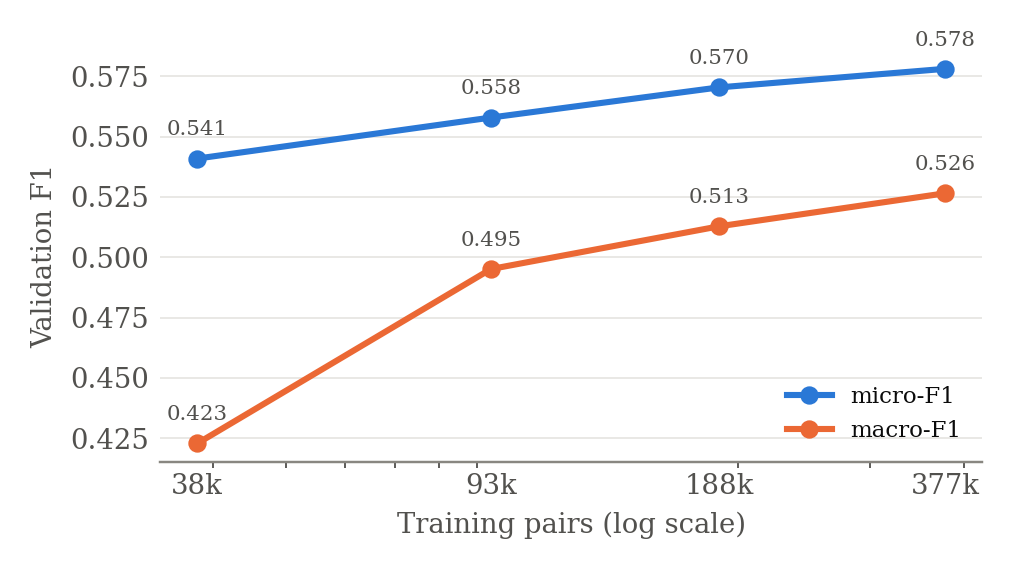

figures/final_test_confusion.png


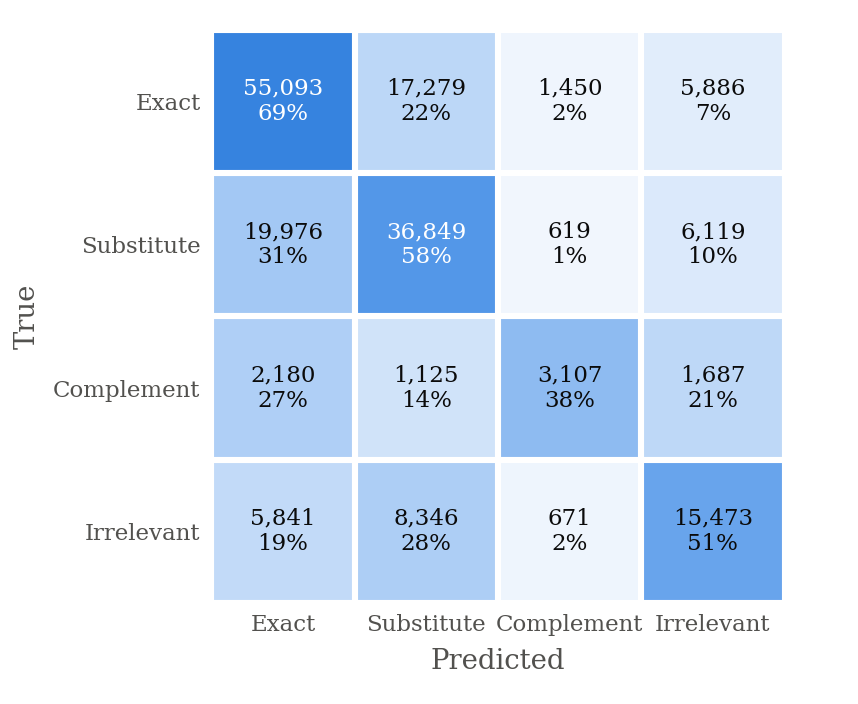

figures/final_test_per_class_f1.png


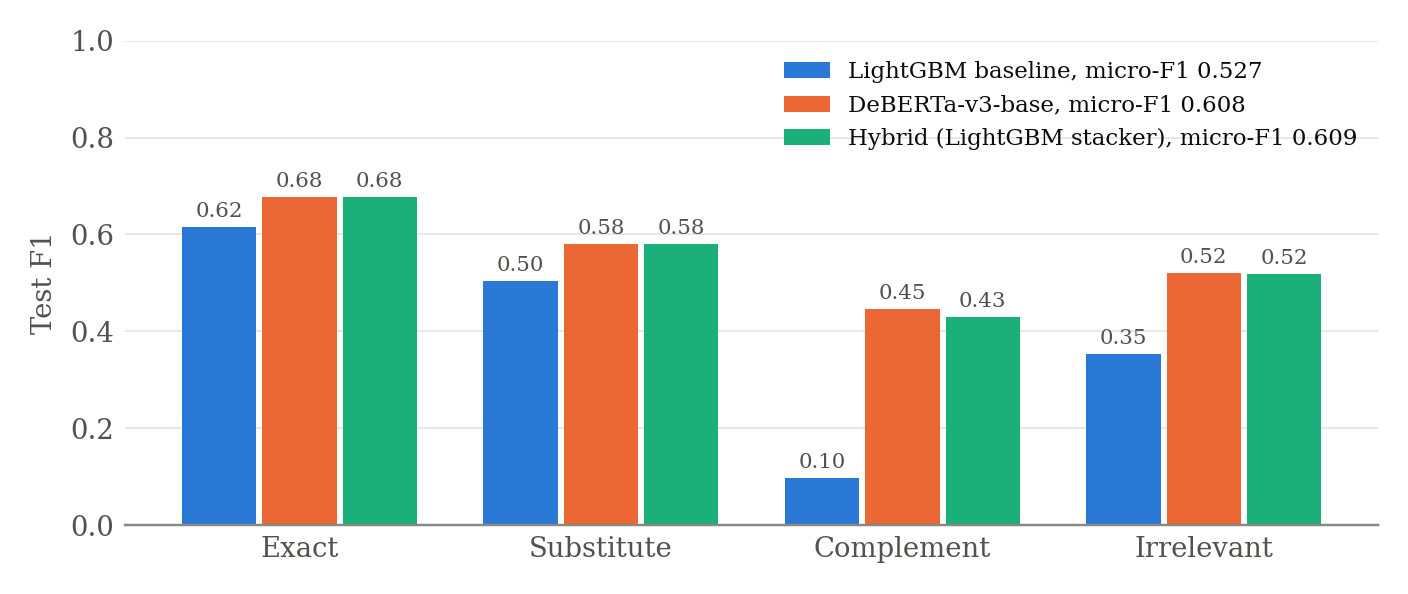

In [28]:
for f in sorted(glob.glob('figures/*.png')):
    print(f); display(Image(f, width=650))